In [1]:

# Install KaggleHub
!pip -q install kagglehub

import kagglehub
import os

# Download CarDD dataset directly from Kaggle
dataset_path = kagglehub.dataset_download(
    "gabrielfcarvalho/cardd-with-yolo-annotations-images-labels"
)

print("Dataset downloaded successfully!")
print("Dataset location:", dataset_path)

# Inspect folder structure
for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level > 2:
        continue

    print("  " * level + os.path.basename(root) + "/")

    for file in files[:5]:
        print("  " * (level + 1) + file)


Using Colab cache for faster access to the 'cardd-with-yolo-annotations-images-labels' dataset.
Dataset downloaded successfully!
Dataset location: /kaggle/input/cardd-with-yolo-annotations-images-labels
cardd-with-yolo-annotations-images-labels/
  data.yaml
  val/
    labels/
      002604.txt
      003708.txt
      000159.txt
      001909.txt
      000825.txt
    images/
      001940.jpg
      000748.jpg
      000857.jpg
      000853.jpg
      003479.jpg
  test/
    labels/
      002801.txt
      003789.txt
      003842.txt
      000796.txt
      003671.txt
    images/
      000875.jpg
      001071.jpg
      001506.jpg
      002056.jpg
      003831.jpg
  train/
    labels/
      000637.txt
      000360.txt
      002979.txt
      000870.txt
      003697.txt
    images/
      000304.jpg
      001229.jpg
      001989.jpg
      000780.jpg
      003113.jpg


In [2]:

import os
import yaml

# Load dataset configuration
yaml_path = os.path.join(dataset_path, "data.yaml")

with open(yaml_path, "r") as file:
    data_config = yaml.safe_load(file)

print("DATASET CONFIGURATION")
print(data_config)

# Count images and label files
for split in ["train", "val", "test"]:
    images_path = os.path.join(dataset_path, split, "images")
    labels_path = os.path.join(dataset_path, split, "labels")

    image_count = len([
        f for f in os.listdir(images_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    label_count = len([
        f for f in os.listdir(labels_path)
        if f.endswith(".txt")
    ])

    print(f"\n{split.upper()}")
    print("Images:", image_count)
    print("Label files:", label_count)


DATASET CONFIGURATION
{'train': '/kaggle/input/cardd-with-yolo-annotations-images-labels/train/images', 'val': '/kaggle/input/cardd-with-yolo-annotations-images-labels/val/images', 'test': '/kaggle/input/cardd-with-yolo-annotations-images-labels/test/images', 'nc': 6, 'names': ['dent', 'scratch', 'crack', 'glass shatter', 'lamp broken', 'tire flat']}

TRAIN
Images: 2816
Label files: 2816

VAL
Images: 810
Label files: 810

TEST
Images: 374
Label files: 374


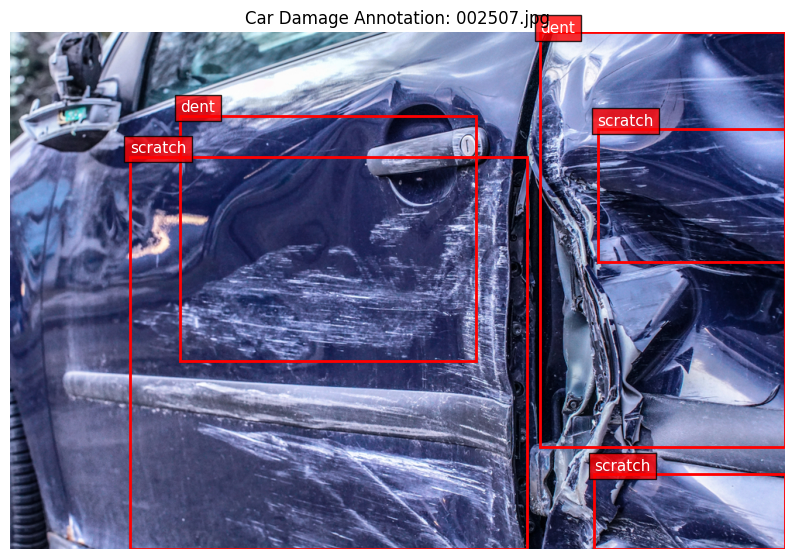

Image: 002507.jpg
Image size: (1000, 667)
Annotation file: 002507.txt


In [3]:

import os
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# Dataset folders
images_dir = os.path.join(dataset_path, "train", "images")
labels_dir = os.path.join(dataset_path, "train", "labels")

# Get images
image_files = [
    f for f in os.listdir(images_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

# Pick an image containing at least one annotation
annotated_images = [
    f for f in image_files
    if os.path.exists(
        os.path.join(
            labels_dir,
            os.path.splitext(f)[0] + ".txt"
        )
    )
    and os.path.getsize(
        os.path.join(
            labels_dir,
            os.path.splitext(f)[0] + ".txt"
        )
    ) > 0
]

image_file = random.choice(annotated_images)

image_path = os.path.join(images_dir, image_file)
label_path = os.path.join(
    labels_dir,
    os.path.splitext(image_file)[0] + ".txt"
)

# Load image
image = Image.open(image_path).convert("RGB")
width, height = image.size

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(image)

# Get class names from data.yaml
class_names = data_config["names"]

# Read YOLO annotations
with open(label_path, "r") as f:
    for line in f:
        values = line.strip().split()

        class_id = int(values[0])
        x, y, w, h = map(float, values[1:5])

        # Convert normalized YOLO coordinates
        box_width = w * width
        box_height = h * height
        x_min = (x - w / 2) * width
        y_min = (y - h / 2) * height

        rect = patches.Rectangle(
            (x_min, y_min),
            box_width,
            box_height,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

        ax.text(
            x_min,
            max(0, y_min - 5),
            class_names[class_id],
            color="white",
            fontsize=11,
            bbox=dict(facecolor="red", alpha=0.8)
        )

ax.set_title(f"Car Damage Annotation: {image_file}")
ax.axis("off")
plt.show()

print("Image:", image_file)
print("Image size:", image.size)
print("Annotation file:", os.path.basename(label_path))


In [4]:

import os
import yaml

# Create configuration with Colab dataset paths
colab_config = {
    "path": dataset_path,
    "train": "train/images",
    "val": "val/images",
    "test": "test/images",
    "nc": 6,
    "names": [
        "dent",
        "scratch",
        "crack",
        "glass shatter",
        "lamp broken",
        "tire flat"
    ]
}

# Save updated configuration
new_yaml_path = "/content/cardd_colab.yaml"

with open(new_yaml_path, "w") as f:
    yaml.safe_dump(
        colab_config,
        f,
        sort_keys=False
    )

# Verify the saved configuration
with open(new_yaml_path, "r") as f:
    print(f.read())

# Check all dataset directories exist
for split in ["train", "val", "test"]:
    folder = os.path.join(
        dataset_path,
        split,
        "images"
    )

    assert os.path.isdir(folder), f"Missing: {folder}"

print("Dataset configuration verified!")


path: /kaggle/input/cardd-with-yolo-annotations-images-labels
train: train/images
val: val/images
test: test/images
nc: 6
names:
- dent
- scratch
- crack
- glass shatter
- lamp broken
- tire flat

Dataset configuration verified!


In [5]:

# Install Ultralytics YOLO
!pip -q install ultralytics

import torch
from ultralytics import YOLO

# Check GPU
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

# Load pretrained YOLO model
model = YOLO("yolo11n.pt")

print("\nYOLO model loaded successfully!")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 10.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4

YOLO model loaded successfully!


In [6]:

from ultralytics import YOLO

# Load pretrained YOLO11 nano model
model = YOLO("yolo11n.pt")

# Train on CarDD
results = model.train(
    data="/content/cardd_colab.yaml",
    epochs=10,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    project="/content/car_damage_runs",
    name="yolo11n_first",
    exist_ok=True,
    seed=42
)

print("Training completed!")
print("Results saved in:")
print(results.save_dir)


Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/cardd_colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_first, nbs=64, nms=None, opset=None, optimize=False, opti

In [8]:

from google.colab import drive
import os
import shutil

# Mount Google Drive
drive.mount("/content/drive")

# Create folder for saved models
save_folder = "/content/drive/MyDrive/Car_Damage_AI/models"
os.makedirs(save_folder, exist_ok=True)

# Save best trained model
source = "/content/car_damage_runs/yolo11n_first/weights/best.pt"
destination = os.path.join(save_folder, "car_damage_yolo11n_best.pt")

shutil.copy2(source, destination)

print("Model saved successfully!")
print("Location:", destination)
print("Size (MB):", round(os.path.getsize(destination) / (1024**2), 2))


Mounted at /content/drive
Model saved successfully!
Location: /content/drive/MyDrive/Car_Damage_AI/models/car_damage_yolo11n_best.pt
Size (MB): 5.2


In [9]:

from ultralytics import YOLO
import os

# Path to our trained model
model_path = "/content/car_damage_runs/yolo11n_first/weights/best.pt"

# If Colab restarted, load from Google Drive instead
if not os.path.exists(model_path):
    model_path = (
        "/content/drive/MyDrive/Car_Damage_AI/models/"
        "car_damage_yolo11n_best.pt"
    )

# Load the trained model
damage_model = YOLO(model_path)

print("Trained model loaded successfully!")
print("Damage classes:", damage_model.names)


Trained model loaded successfully!
Damage classes: {0: 'dent', 1: 'scratch', 2: 'crack', 3: 'glass shatter', 4: 'lamp broken', 5: 'tire flat'}


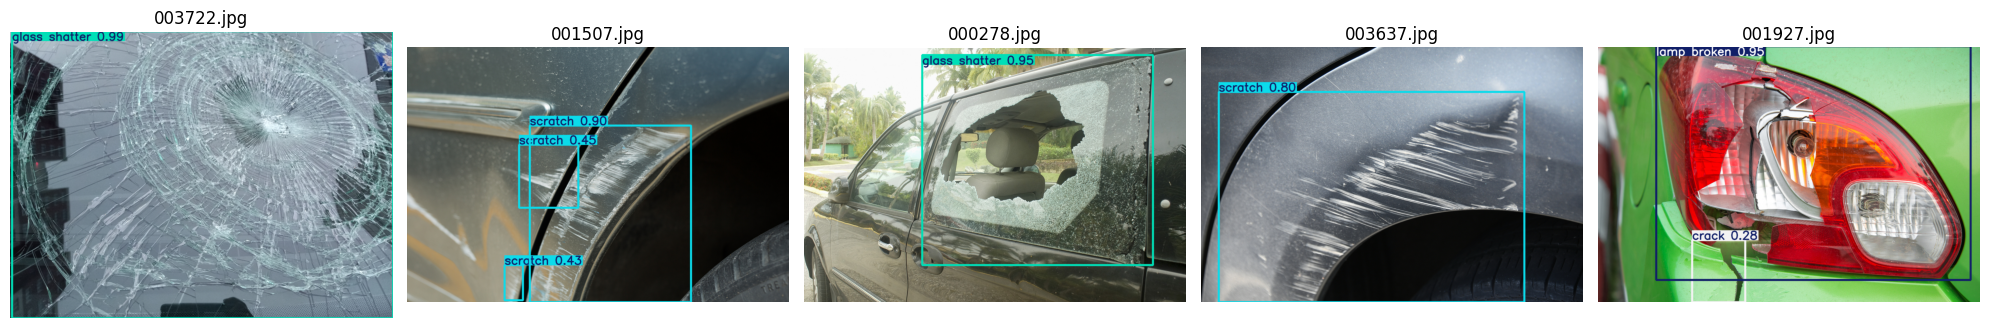

In [10]:

import os
import random
import matplotlib.pyplot as plt
from PIL import Image

# Validation images directory
val_images_dir = os.path.join(
    dataset_path, "val", "images"
)

# Select five random validation images
random.seed(42)

image_files = random.sample(
    [
        f for f in os.listdir(val_images_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ],
    5
)

image_paths = [
    os.path.join(val_images_dir, f)
    for f in image_files
]

# Run YOLO predictions
predictions = damage_model.predict(
    source=image_paths,
    conf=0.25,
    imgsz=640,
    device=0,
    verbose=False
)

# Display the predictions
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, result in zip(axes, predictions):
    annotated_image = result.plot()

    # Convert BGR to RGB
    annotated_image = annotated_image[:, :, ::-1]

    ax.imshow(annotated_image)
    ax.set_title(os.path.basename(result.path))
    ax.axis("off")

plt.tight_layout()
plt.show()


In [11]:

for result in predictions:
    print("\nImage:", os.path.basename(result.path))

    if len(result.boxes) == 0:
        print("No damage detected at this threshold")
        continue

    for box in result.boxes:
        class_id = int(box.cls.item())
        confidence = float(box.conf.item())

        print(
            f"Damage: {damage_model.names[class_id]} | "
            f"Confidence: {confidence:.2%}"
        )



Image: 003722.jpg
Damage: glass shatter | Confidence: 98.79%

Image: 001507.jpg
Damage: scratch | Confidence: 90.14%
Damage: scratch | Confidence: 44.60%
Damage: scratch | Confidence: 43.47%

Image: 000278.jpg
Damage: glass shatter | Confidence: 95.47%

Image: 003637.jpg
Damage: scratch | Confidence: 79.64%

Image: 001927.jpg
Damage: lamp broken | Confidence: 94.68%
Damage: crack | Confidence: 28.08%


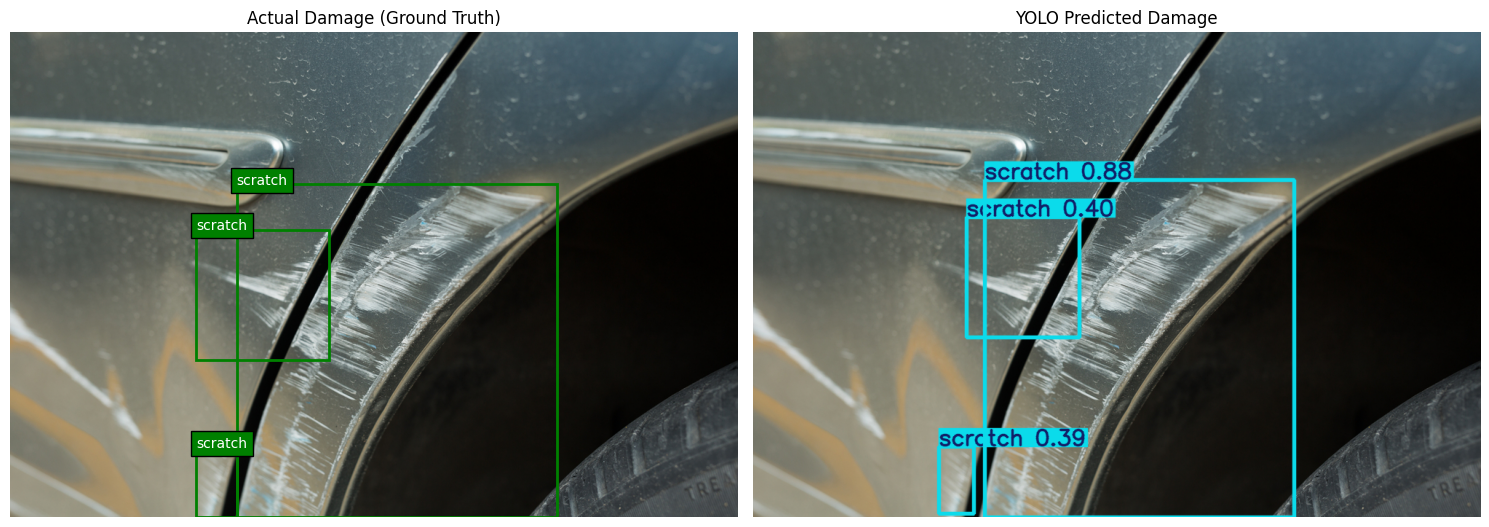

In [12]:

import os
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# Choose an image with multiple predicted scratches
image_name = "001507.jpg"

image_path = os.path.join(
    dataset_path, "val", "images", image_name
)

label_path = os.path.join(
    dataset_path, "val", "labels",
    image_name.replace(".jpg", ".txt")
)

# Load image
image = Image.open(image_path).convert("RGB")
width, height = image.size

# Predict using trained YOLO
result = damage_model.predict(
    image_path,
    conf=0.25,
    verbose=False
)[0]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# LEFT: Ground truth annotations
axes[0].imshow(image)

with open(label_path, "r") as f:
    for line in f:
        cls, x, y, w, h = map(float, line.split())

        x_min = (x - w / 2) * width
        y_min = (y - h / 2) * height

        rect = patches.Rectangle(
            (x_min, y_min),
            w * width,
            h * height,
            fill=False,
            edgecolor="green",
            linewidth=2
        )

        axes[0].add_patch(rect)
        axes[0].text(
            x_min, y_min,
            damage_model.names[int(cls)],
            color="white",
            bbox=dict(facecolor="green")
        )

axes[0].set_title("Actual Damage (Ground Truth)")
axes[0].axis("off")

# RIGHT: YOLO predictions
predicted_image = result.plot()[:, :, ::-1]

axes[1].imshow(predicted_image)
axes[1].set_title("YOLO Predicted Damage")
axes[1].axis("off")

plt.tight_layout()
plt.show()


In [13]:

from ultralytics import YOLO

# Load our previously trained best model
model = YOLO(
    "/content/car_damage_runs/yolo11n_first/weights/best.pt"
)

# Continue fine-tuning
results_improved = model.train(
    data="/content/cardd_colab.yaml",
    epochs=20,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    project="/content/car_damage_runs",
    name="yolo11n_improved",
    seed=42
)

print("Improved training completed!")
print("Results saved to:", results_improved.save_dir)


Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/cardd_colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/car_damage_runs/yolo11n_first/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_improved, nb

In [14]:

from google.colab import drive
import os
import shutil

# Mount Google Drive
drive.mount("/content/drive")

# Create model folder
save_folder = "/content/drive/MyDrive/Car_Damage_AI/models"
os.makedirs(save_folder, exist_ok=True)

# Copy improved model weights
source = (
    "/content/car_damage_runs/"
    "yolo11n_improved/weights/best.pt"
)

destination = os.path.join(
    save_folder,
    "car_damage_yolo11n_improved.pt"
)

shutil.copy2(source, destination)

print("Improved model saved successfully!")
print("Location:", destination)
print(
    "Size (MB):",
    round(os.path.getsize(destination) / 1024**2, 2)
)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Improved model saved successfully!
Location: /content/drive/MyDrive/Car_Damage_AI/models/car_damage_yolo11n_improved.pt
Size (MB): 5.2


In [15]:

from ultralytics import YOLO

# Load our best improved model
model = YOLO(
    "/content/car_damage_runs/yolo11n_improved/weights/best.pt"
)

# Evaluate on the reserved TEST dataset
test_results = model.val(
    data="/content/cardd_colab.yaml",
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    plots=True,
    project="/content/car_damage_runs",
    name="final_test_evaluation"
)

print("\n===== FINAL TEST RESULTS =====")

print("Precision:", round(test_results.box.mp * 100, 2), "%")
print("Recall:", round(test_results.box.mr * 100, 2), "%")
print("mAP@50:", round(test_results.box.map50 * 100, 2), "%")
print("mAP@50-95:", round(test_results.box.map * 100, 2), "%")


Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,583,322 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.1±0.2 ms, read: 51.6±10.2 MB/s, size: 632.2 KB)
val: Scanning /kaggle/input/cardd-with-yolo-annotations-images-labels/test/labels... 374 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 374/374 64.7it/s 5.8s
WARNING ⚠️ val: Cache directory /kaggle/input/cardd-with-yolo-annotations-images-labels/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 47/47 4.2it/s 11.3s
                   all        374        785      0.711      0.604      0.672       0.53
                  dent        157        236      0.704      0.463      0.561      0.334
               scratch        183        307       0.68      0.466      0.585      0.312
                 crack         48         70      0.358      0.257

In [16]:

from ultralytics import YOLO
import os
import pandas as pd

# Load improved model
model = YOLO(
    "/content/car_damage_runs/yolo11n_improved/weights/best.pt"
)

# Use a validation image
image_path = os.path.join(
    dataset_path, "val", "images", "001507.jpg"
)

# Run prediction
result = model.predict(
    source=image_path,
    conf=0.25,
    verbose=False
)[0]

image_height, image_width = result.orig_shape

damage_data = []

for box in result.boxes:
    class_id = int(box.cls.item())
    confidence = float(box.conf.item())

    x1, y1, x2, y2 = box.xyxy[0].tolist()

    box_area = max(0, x2 - x1) * max(0, y2 - y1)
    image_area = image_width * image_height

    box_coverage = (box_area / image_area) * 100

    damage_data.append({
        "Damage Type": model.names[class_id],
        "Confidence (%)": round(confidence * 100, 2),
        "Box Width (px)": round(x2 - x1, 1),
        "Box Height (px)": round(y2 - y1, 1),
        "Image Coverage (%)": round(box_coverage, 2)
    })

damage_df = pd.DataFrame(damage_data)

display(damage_df)


,Damage Type,Confidence (%),Box Width (px),Box Height (px),Image Coverage (%)
0,scratch,91.25,436.3,574.1,37.55
1,scratch,71.62,49.3,96.3,0.71
2,scratch,45.42,210.1,177.3,5.58
3,scratch,30.51,249.2,316.4,11.82


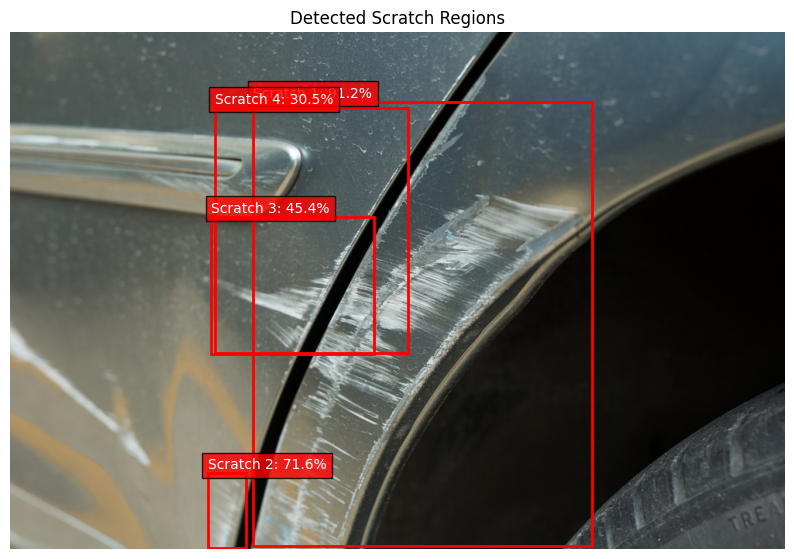

In [17]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Display original image
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(result.orig_img[:, :, ::-1])

# Draw each predicted bounding box
for i, box in enumerate(result.boxes):
    x1, y1, x2, y2 = box.xyxy[0].tolist()

    confidence = float(box.conf.item())

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)

    ax.text(
        x1,
        max(0, y1 - 5),
        f"Scratch {i+1}: {confidence:.1%}",
        color="white",
        fontsize=10,
        bbox=dict(facecolor="red", alpha=0.8)
    )

ax.set_title("Detected Scratch Regions")
ax.axis("off")
plt.show()


In [18]:

import os

label_dir = os.path.join(
    dataset_path, "train", "labels"
)

label_files = [
    f for f in os.listdir(label_dir)
    if f.endswith(".txt")
]

# Examine first five nonempty labels
for filename in label_files[:5]:
    path = os.path.join(label_dir, filename)

    with open(path, "r") as f:
        lines = [line.strip() for line in f if line.strip()]

    print("\nFile:", filename)

    if lines:
        print("Example annotation:", lines[0])
        print("Number of values:", len(lines[0].split()))
    else:
        print("Empty annotation")



File: 000637.txt
Example annotation: 0 0.744195 0.481807 0.155970 0.195577
Number of values: 5

File: 000360.txt
Example annotation: 1 0.535230 0.507534 0.273200 0.388531
Number of values: 5

File: 002979.txt
Example annotation: 0 0.689595 0.408178 0.304110 0.490750
Number of values: 5

File: 000870.txt
Example annotation: 0 0.560215 0.273793 0.206550 0.265937
Number of values: 5

File: 003697.txt
Example annotation: 0 0.826570 0.362106 0.090540 0.126012
Number of values: 5


In [5]:

from google.colab import drive
from ultralytics import YOLO
import os

# Connect Google Drive
drive.mount("/content/drive")

# Previously saved improved model
model_path = (
    "/content/drive/MyDrive/Car_Damage_AI/models/"
    "car_damage_yolo11n_improved.pt"
)

if os.path.exists(model_path):
    model = YOLO(model_path)
    print("Improved YOLO model loaded successfully!")
    print("Classes:", model.names)
else:
    print("Model not found at the expected location.")


Mounted at /content/drive
Improved YOLO model loaded successfully!
Classes: {0: 'dent', 1: 'scratch', 2: 'crack', 3: 'glass shatter', 4: 'lamp broken', 5: 'tire flat'}


In [7]:

import os
import kagglehub

# Check whether the dataset is available
dataset_path = kagglehub.dataset_download(
    "gabrielfcarvalho/cardd-with-yolo-annotations-images-labels"
)

print("Dataset location:", dataset_path)

# Check validation images
val_images = os.path.join(
    dataset_path, "val", "images"
)

print("Validation folder exists:", os.path.exists(val_images))

# Check our example image
image_path = os.path.join(
    val_images,
    "001507.jpg"
)

print("Example image exists:", os.path.exists(image_path))

# Confirm restored model
print("Model classes:", model.names)


100%|██████████| 2.80G/2.80G [00:32<00:00, 91.6MB/s]

Extracting files...


Dataset location: /root/.cache/kagglehub/datasets/gabrielfcarvalho/cardd-with-yolo-annotations-images-labels/versions/2
Validation folder exists: True
Example image exists: True
Model classes: {0: 'dent', 1: 'scratch', 2: 'crack', 3: 'glass shatter', 4: 'lamp broken', 5: 'tire flat'}


In [8]:

import pandas as pd
import os

# Select validation image
image_path = os.path.join(
    dataset_path, "val", "images", "001507.jpg"
)

# Use our restored trained model
result = model.predict(
    source=image_path,
    conf=0.25,
    imgsz=640,
    verbose=False
)[0]

# Get original image dimensions
height, width = result.orig_shape
image_area = height * width

damage_records = []

for box in result.boxes:
    class_id = int(box.cls.item())
    damage_type = model.names[class_id]
    confidence = float(box.conf.item())

    # Bounding-box coordinates
    x1, y1, x2, y2 = box.xyxy[0].tolist()

    box_area = max(0, x2-x1) * max(0, y2-y1)
    coverage = (box_area / image_area) * 100

    # Preliminary inspection-priority rules
    if damage_type in [
        "glass shatter",
        "lamp broken",
        "tire flat"
    ]:
        priority = "Prompt inspection"
    else:
        priority = "Visual review required"

    damage_records.append({
        "Damage Type": damage_type,
        "Confidence (%)": round(confidence * 100, 2),
        "Image Coverage (%)": round(coverage, 2),
        "Inspection Priority": priority,
        "Severity": "Not yet assessed"
    })

assessment_df = pd.DataFrame(
    damage_records,
    columns=[
        "Damage Type",
        "Confidence (%)",
        "Image Coverage (%)",
        "Inspection Priority",
        "Severity"
    ]
)

display(assessment_df)


,Damage Type,Confidence (%),Image Coverage (%),Inspection Priority,Severity
0,scratch,91.25,37.55,Visual review required,Not yet assessed
1,scratch,71.62,0.71,Visual review required,Not yet assessed
2,scratch,45.42,5.58,Visual review required,Not yet assessed
3,scratch,30.51,11.82,Visual review required,Not yet assessed


In [3]:

%pip install -q ultralytics


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 32.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 9.4 MB/s eta 0:00:00


In [9]:

import pandas as pd

# Count detected damage types
damage_counts = assessment_df["Damage Type"].value_counts()

# Summarize detections
image_summary = {
    "Total Detections": len(assessment_df),
    "Damage Types": ", ".join(damage_counts.index),
    "Highest Confidence (%)": (
        assessment_df["Confidence (%)"].max()
    ),
    "Average Confidence (%)": round(
        assessment_df["Confidence (%)"].mean(), 2
    ),
    "Largest Box Coverage (%)": (
        assessment_df["Image Coverage (%)"].max()
    ),
    "Inspection Required": (
        "Yes" if len(assessment_df) > 0 else "No detection"
    ),
    "Physical Severity": "Unknown"
}

summary_df = pd.DataFrame([image_summary])

display(summary_df)


,Total Detections,Damage Types,Highest Confidence (%),Average Confidence (%),Largest Box Coverage (%),Inspection Required,Physical Severity
0,4,scratch,91.25,59.7,37.55,Yes,Unknown


In [10]:

from itertools import combinations
from ultralytics.utils.metrics import bbox_ioa
import torch
import pandas as pd

# Extract predicted boxes
boxes = result.boxes.xyxy.cpu()

def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)

    area1 = (box1[2]-box1[0]) * (box1[3]-box1[1])
    area2 = (box2[2]-box2[0]) * (box2[3]-box2[1])

    union = area1 + area2 - intersection

    return float(intersection / union) if union > 0 else 0

overlap_records = []

for i, j in combinations(range(len(boxes)), 2):
    iou = calculate_iou(boxes[i].tolist(), boxes[j].tolist())

    overlap_records.append({
        "Detection Pair": f"{i+1} and {j+1}",
        "IoU (%)": round(iou * 100, 2),
        "Substantial Overlap": "Yes" if iou >= 0.5 else "No"
    })

overlap_df = pd.DataFrame(overlap_records)

display(overlap_df)


,Detection Pair,IoU (%),Substantial Overlap
0,1 and 2,0.00,No
1,1 and 3,10.61,No
2,1 and 4,23.74,No
3,2 and 3,0.00,No
4,2 and 4,0.00,No
5,3 and 4,45.11,No


In [11]:

# Build a consolidated damage-assessment report

damage_types = sorted(
    assessment_df["Damage Type"].unique().tolist()
)

highest_confidence = assessment_df["Confidence (%)"].max()

max_overlap = (
    overlap_df["IoU (%)"].max()
    if not overlap_df.empty else 0
)

safety_related = [
    "glass shatter",
    "lamp broken",
    "tire flat"
]

if any(d in safety_related for d in damage_types):
    inspection_priority = "Prompt inspection"
elif damage_types:
    inspection_priority = "Visual review required"
else:
    inspection_priority = "No detection"

report = {
    "Image": os.path.basename(image_path),
    "Detected Damage": ", ".join(damage_types) or "None",
    "Number of Detections": len(assessment_df),
    "Highest Confidence (%)": round(highest_confidence, 2),
    "Maximum Box Overlap (%)": round(max_overlap, 2),
    "Inspection Priority": inspection_priority,
    "Physical Severity": "Unknown",
    "Repair Cost": "Not yet estimated",
}

report_df = pd.DataFrame([report])

display(report_df)


,Image,Detected Damage,Number of Detections,Highest Confidence (%),Maximum Box Overlap (%),Inspection Priority,Physical Severity,Repair Cost
0,001507.jpg,scratch,4,91.25,45.11,Visual review required,Unknown,Not yet estimated


In [12]:

import pandas as pd

def estimate_repair_cost(
    repair_method,
    labor_hours,
    hourly_labor_rate,
    materials_cost,
    parts_cost=0
):
    labor_cost = labor_hours * hourly_labor_rate

    total_cost = (
        labor_cost
        + materials_cost
        + parts_cost
    )

    return {
        "Repair Method": repair_method,
        "Labor Hours": labor_hours,
        "Hourly Labor Rate": hourly_labor_rate,
        "Labor Cost": round(labor_cost, 2),
        "Materials Cost": materials_cost,
        "Parts Cost": parts_cost,
        "Estimated Total": round(total_cost, 2)
    }

# Demonstration inputs only — not verified market rates
repair_result = estimate_repair_cost(
    repair_method="Scratch polishing",
    labor_hours=2,
    hourly_labor_rate=25,
    materials_cost=15,
    parts_cost=0
)

display(pd.DataFrame([repair_result]))


,Repair Method,Labor Hours,Hourly Labor Rate,Labor Cost,Materials Cost,Parts Cost,Estimated Total
0,Scratch polishing,2,25,50,15,0,65


In [13]:

import pandas as pd

# UK repair-cost references in GBP
# Indicative 2026 prices, not binding quotations

repair_prices = {
    "Clear-coat scratch repair": (60, 96),
    "Paintwork scratch repair": (120, 180),
    "Deep scratch repair": (180, 240),
    "Full-panel repaint": (350, 600)
}

# Build our UK repair reference table
uk_repair_df = pd.DataFrame([
    {
        "Repair Method": method,
        "Minimum Cost (£)": prices[0],
        "Maximum Cost (£)": prices[1],
        "Midpoint (£)": (prices[0] + prices[1]) / 2
    }
    for method, prices in repair_prices.items()
])

display(uk_repair_df)

# Example: choose a possible repair method manually
selected_method = "Paintwork scratch repair"

minimum, maximum = repair_prices[selected_method]

print("\nDetected damage: Scratch")
print("Selected repair:", selected_method)
print(f"Indicative UK repair cost: £{minimum} - £{maximum}")
print("Note: Repair method requires human verification.")


,Repair Method,Minimum Cost (£),Maximum Cost (£),Midpoint (£)
0,Clear-coat scratch repair,60,96,78.0
1,Paintwork scratch repair,120,180,150.0
2,Deep scratch repair,180,240,210.0
3,Full-panel repaint,350,600,475.0



Detected damage: Scratch
Selected repair: Paintwork scratch repair
Indicative UK repair cost: £120 - £180
Note: Repair method requires human verification.


In [14]:

import pandas as pd

# Select repair method manually for this example
selected_repair = "Paintwork scratch repair"

# Look up UK reference prices
min_cost, max_cost = repair_prices[selected_repair]

# Combine the existing damage report with repair costs
final_report = report_df.copy()

final_report["Repair Method"] = selected_repair
final_report["Minimum Repair Cost (£)"] = min_cost
final_report["Maximum Repair Cost (£)"] = max_cost
final_report["Midpoint Cost (£)"] = (
    min_cost + max_cost
) / 2

final_report["Estimate Status"] = (
    "Indicative only - repair method requires verification"
)

display(final_report.T)


,0
Image,001507.jpg
Detected Damage,scratch
Number of Detections,4
Highest Confidence (%),91.25
Maximum Box Overlap (%),45.11
Inspection Priority,Visual review required
Physical Severity,Unknown
Repair Cost,Not yet estimated
Repair Method,Paintwork scratch repair
Minimum Repair Cost (£),120


In [15]:

# Map YOLO damage classes to possible repair methods
damage_repair_options = {
    "scratch": [
        "Clear-coat scratch repair",
        "Paintwork scratch repair",
        "Deep scratch repair",
        "Full-panel repaint"
    ],
    "dent": [
        "Paintless dent removal",
        "Dent repair and repaint"
    ],
    "crack": [
        "Panel repair",
        "Panel replacement"
    ],
    "glass shatter": [
        "Automotive glass replacement"
    ],
    "lamp broken": [
        "Lamp assembly replacement"
    ],
    "tire flat": [
        "Puncture repair",
        "Tire replacement"
    ]
}

# Get damage types from our AI report
detected_types = [
    name.strip()
    for name in report_df.loc[0, "Detected Damage"].split(",")
    if name.strip() and name.strip() != "None"
]

# Display possible repair methods
for damage_type in detected_types:
    print(f"\nDetected damage: {damage_type}")

    options = damage_repair_options.get(
        damage_type, ["Professional inspection required"]
    )

    print("Possible repair methods:")
    for number, option in enumerate(options, 1):
        print(f"{number}. {option}")

# Update the existing cost report to avoid conflicting fields
final_report["Repair Cost"] = final_report.apply(
    lambda row: (
        f"£{row['Minimum Repair Cost (£)']:.0f}"
        f" - £{row['Maximum Repair Cost (£)']:.0f}"
    ),
    axis=1
)

print("\nUpdated repair-cost report:")
display(final_report.T)



Detected damage: scratch
Possible repair methods:
1. Clear-coat scratch repair
2. Paintwork scratch repair
3. Deep scratch repair
4. Full-panel repaint

Updated repair-cost report:


,0
Image,001507.jpg
Detected Damage,scratch
Number of Detections,4
Highest Confidence (%),91.25
Maximum Box Overlap (%),45.11
Inspection Priority,Visual review required
Physical Severity,Unknown
Repair Cost,£120 - £180
Repair Method,Paintwork scratch repair
Minimum Repair Cost (£),120


In [16]:

import os
import pandas as pd
from IPython.display import display

def analyze_car_damage(image_path, confidence=0.25):

    # 1. Run trained YOLO model
    result = model.predict(
        source=image_path,
        conf=confidence,
        imgsz=640,
        verbose=False
    )[0]

    detections = []

    # 2. Extract detected damage
    for box in result.boxes:

        damage_type = model.names[int(box.cls.item())]
        score = float(box.conf.item()) * 100

        detections.append({
            "Damage Type": damage_type,
            "Confidence (%)": round(score, 2)
        })

    detection_df = pd.DataFrame(
        detections,
        columns=["Damage Type", "Confidence (%)"]
    )

    # 3. Summarize damage categories
    damage_types = sorted(
        detection_df["Damage Type"].unique().tolist()
    )

    # 4. Determine inspection priority
    safety_related = {
        "glass shatter",
        "lamp broken",
        "tire flat"
    }

    if any(d in safety_related for d in damage_types):
        priority = "Prompt inspection"
    elif damage_types:
        priority = "Visual review required"
    else:
        priority = "No damage detected by model"

    # 5. Suggest potential repair methods
    repair_suggestions = {
        damage: damage_repair_options.get(
            damage,
            ["Professional assessment required"]
        )
        for damage in damage_types
    }

    # 6. Generate report
    report = {
        "Image": os.path.basename(image_path),
        "Damage Types": ", ".join(damage_types) or "None detected",
        "Total Detections": len(detection_df),
        "Inspection Priority": priority,
        "Physical Severity": "Not assessed",
        "Suggested Repairs": repair_suggestions
    }

    return result, detection_df, report


# TEST THE FUNCTION
test_image = os.path.join(
    dataset_path, "val", "images", "001507.jpg"
)

result, detections, report = analyze_car_damage(test_image)

print("DETAILED DETECTIONS")
display(detections)

print("\nIMAGE ASSESSMENT REPORT")
for key, value in report.items():
    print(f"{key}: {value}")


DETAILED DETECTIONS


,Damage Type,Confidence (%)
0,scratch,91.25
1,scratch,71.62
2,scratch,45.42
3,scratch,30.51



IMAGE ASSESSMENT REPORT
Image: 001507.jpg
Damage Types: scratch
Total Detections: 4
Inspection Priority: Visual review required
Physical Severity: Not assessed
Suggested Repairs: {'scratch': ['Clear-coat scratch repair', 'Paintwork scratch repair', 'Deep scratch repair', 'Full-panel repaint']}


Saving images.jpg to images.jpg


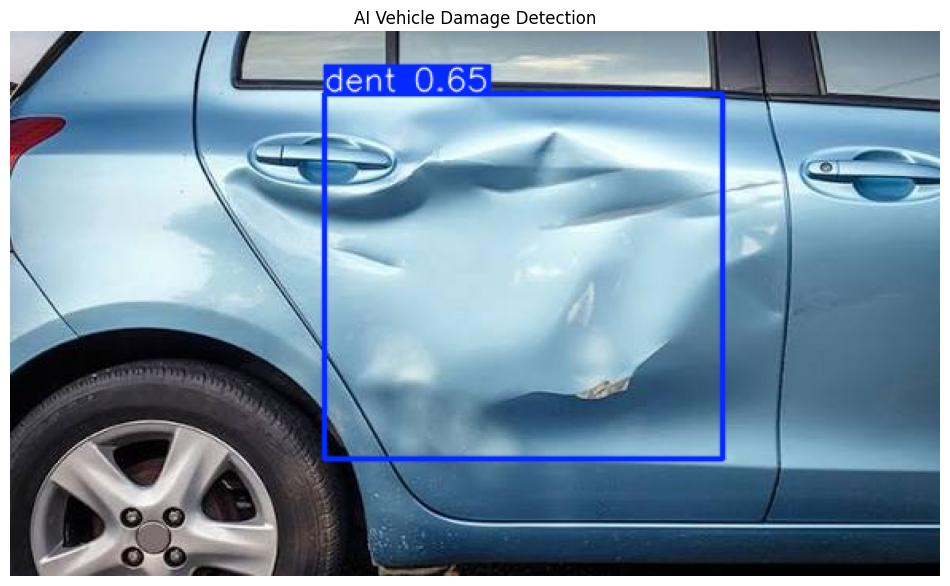

DETAILED DETECTIONS


,Damage Type,Confidence (%)
0,dent,64.61



VEHICLE DAMAGE ASSESSMENT
Image: images.jpg
Damage Types: dent
Total Detections: 1
Inspection Priority: Visual review required
Physical Severity: Not assessed
Suggested Repairs: {'dent': ['Paintless dent removal', 'Dent repair and repaint']}


In [17]:

from google.colab import files
from IPython.display import display
import matplotlib.pyplot as plt
import os

# 1. Upload your own car image
uploaded = files.upload()

if uploaded:
    # 2. Get the uploaded image path
    image_path = os.path.abspath(
        next(iter(uploaded.keys()))
    )

    # 3. Analyze using our trained AI model
    result, detections, report = analyze_car_damage(
        image_path
    )

    # 4. Display YOLO predictions
    annotated_image = result.plot()

    plt.figure(figsize=(12, 8))
    plt.imshow(annotated_image[:, :, ::-1])
    plt.title("AI Vehicle Damage Detection")
    plt.axis("off")
    plt.show()

    # 5. Display detected damage
    print("DETAILED DETECTIONS")
    display(detections)

    # 6. Display assessment report
    print("\nVEHICLE DAMAGE ASSESSMENT")

    for key, value in report.items():
        print(f"{key}: {value}")
